In [ ]:
!pip install ucimlrepo pandas numpy


In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

bank = fetch_ucirepo(id=222)

X = bank.data.features
y = bank.data.targets

df = X.copy()
df["y"] = y.iloc[:, 0]

print(df.head())
print("Dataset Shape:", df.shape)

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome   y  
0     NaN            5   may       261         1     -1         0      NaN  no  
1     NaN            5   may       151         1     -1         0      NaN  no  
2     NaN            5   may        76         1     -1         0      NaN  no  
3     NaN            5   may        92         1     -1         0      NaN  no  
4     NaN            5   may       198         1     -1         0      NaN  no  
Dataset Shape: (45211, 17)


In [ ]:
X = df.drop("y", axis=1)

y = df["y"]

print("Features:", X.shape)
print("Target:", y.shape)

print(y.value_counts())

Features: (45211, 16)
Target: (45211,)
y
no     39922
yes     5289
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36168, 16)
Testing data: (9043, 16)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = X.select_dtypes(
    include=["number"]
).columns

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
# Predict using the trained Decision Tree
pred_tree = tree_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(pred_tree[:10])

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    pred_tree,
    zero_division=0
))

              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7985
         yes       0.65      0.30      0.41      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.64      0.68      9043
weighted avg       0.88      0.90      0.88      9043



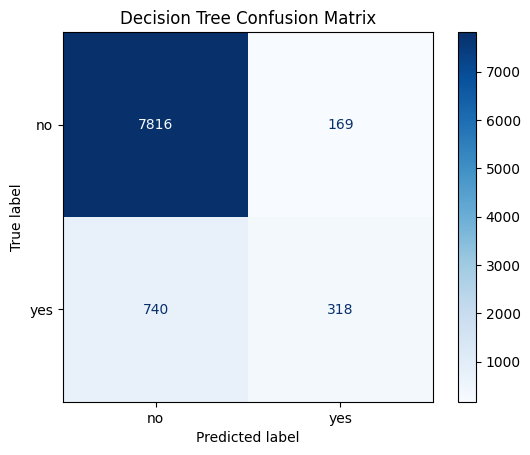

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_tree,
    labels=["no", "yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Create KNN pipeline
knn_model = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=7,
        n_jobs=1
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
pred_knn = knn_model.predict(X_test)

print("First 10 KNN predictions:")
print(pred_knn[:10])

First 10 KNN predictions:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    pred_knn,
    zero_division=0
))

              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7985
         yes       0.63      0.32      0.42      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.65      0.68      9043
weighted avg       0.88      0.90      0.88      9043



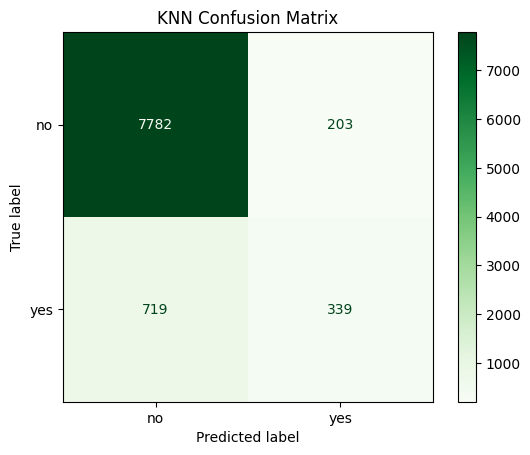

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_knn,
    labels=["no", "yes"],
    cmap="Greens",
    values_format="d"
)

plt.title("KNN Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Create comparison table
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [
        accuracy_score(y_test, pred_tree),
        accuracy_score(y_test, pred_knn)
    ],
    "Precision": [
        precision_score(y_test, pred_tree, pos_label="yes"),
        precision_score(y_test, pred_knn, pos_label="yes")
    ],
    "Recall": [
        recall_score(y_test, pred_tree, pos_label="yes"),
        recall_score(y_test, pred_knn, pos_label="yes")
    ],
    "F1 Score": [
        f1_score(y_test, pred_tree, pos_label="yes"),
        f1_score(y_test, pred_knn, pos_label="yes")
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.8995,0.6530,0.3006,0.4117
1,KNN,0.8980,0.6255,0.3204,0.4238


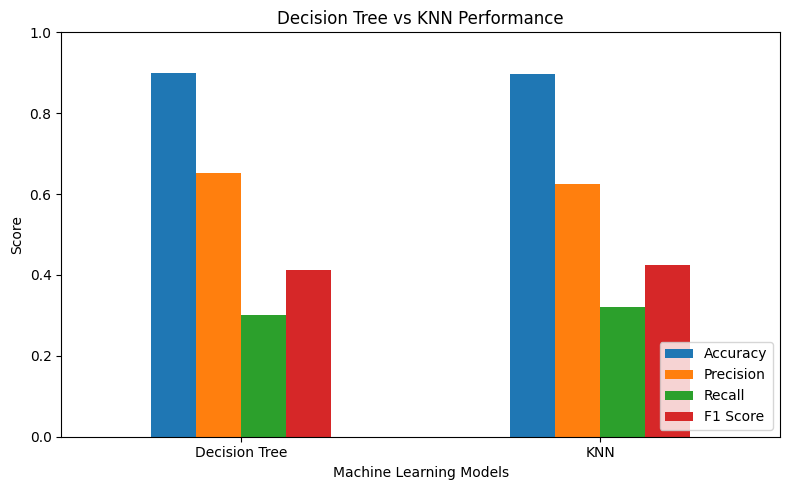

In [ ]:
import matplotlib.pyplot as plt

results.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Decision Tree vs KNN Performance")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

cm_tree = confusion_matrix(
    y_test, pred_tree, labels=["no", "yes"]
)

cm_knn = confusion_matrix(
    y_test, pred_knn, labels=["no", "yes"]
)

print("Decision Tree:")
print("False Positives:", cm_tree[0, 1])
print("False Negatives:", cm_tree[1, 0])

print("\nKNN:")
print("False Positives:", cm_knn[0, 1])
print("False Negatives:", cm_knn[1, 0])

Decision Tree:
False Positives: 169
False Negatives: 740

KNN:
False Positives: 203
False Negatives: 719


nterpretation:

The Bank Marketing dataset was used to train two machine learning models: Decision Tree and KNN. Both models were evaluated using accuracy, precision, recall, and F1-score. The comparison chart shows the performance of both models. False positives represent wasted marketing resources, while false negatives represent missed potential customers. The model with better performance should be selected based on the evaluation metrics and business requirements.

problems and solutions
Problem	Solution
Dataset loading	Used UCI dataset through Python
Different data types	Applied preprocessing
Categorical values	Used OneHotEncoder
Different numerical scales	Used StandardScaler
Model evaluation	Used classification metrics